In [ ]:
!pip install -q -U datasets huggingface_hub pillow scikit-learn tqdm

In [11]:
import csv
import random
from pathlib import Path

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt


from io import BytesIO

from PIL import Image
from datasets import load_dataset
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from torchvision.models import (
    convnext_small,
    ConvNeXt_Small_Weights
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from tqdm.auto import tqdm

In [12]:
DATASET_NAME = "saberzl/SID_Set"

SEED = 42
IMAGE_SIZE = (224, 224)

TARGET_PER_CLASS = {
    0: 16_666,
    1: 16_667,
    2: 16_667,
}

CLASS_NAMES = {
    0: "real",
    1: "full_synthetic",
    2: "tampered",
}

In [13]:
PROCESSED_DIR = Path(
    "/kaggle/working/sid_set_50000_processed"
)

CSV_PATH = PROCESSED_DIR / "labels.csv"

TOTAL_TARGET = sum(
    TARGET_PER_CLASS.values()
)

print("Total target:", TOTAL_TARGET)

Total target: 50000


In [14]:
SPLIT_QUOTAS = {}

for label, total in TARGET_PER_CLASS.items():

    train_n = round(
        total * 0.70
    )

    val_n = round(
        total * 0.15
    )

    test_n = (
        total
        - train_n
        - val_n
    )

    SPLIT_QUOTAS[label] = {
        "train": train_n,
        "val": val_n,
        "test": test_n,
    }

SPLIT_QUOTAS

{0: {'train': 11666, 'val': 2500, 'test': 2500},
 1: {'train': 11667, 'val': 2500, 'test': 2500},
 2: {'train': 11667, 'val': 2500, 'test': 2500}}

In [15]:
SPLIT_PLAN = {}

for label, quotas in SPLIT_QUOTAS.items():

    plan = (
        ["train"] * quotas["train"]
        + ["val"] * quotas["val"]
        + ["test"] * quotas["test"]
    )

    random.Random(
        SEED + label
    ).shuffle(plan)

    SPLIT_PLAN[label] = plan

In [16]:
if CSV_PATH.exists():

    raise FileExistsError(
        f"Dataset already exists at: {PROCESSED_DIR}"
    )


for split in (
    "train",
    "val",
    "test"
):

    for class_name in CLASS_NAMES.values():

        (
            PROCESSED_DIR
            / split
            / class_name
        ).mkdir(
            parents=True,
            exist_ok=True
        )

In [17]:
dataset = load_dataset(
    DATASET_NAME,
    split="train",
    streaming=True,
)

dataset = dataset.shuffle(
    seed=SEED,
    buffer_size=2000,
)

print(dataset)

README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/249 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/34 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/249 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/34 [00:00<?, ?it/s]

IterableDataset({
    features: ['img_id', 'image', 'mask', 'width', 'height', 'label'],
    num_shards: 24
})


In [18]:
def to_pil_image(image):

    if isinstance(
        image,
        Image.Image
    ):

        return image.convert(
            "RGB"
        )


    if isinstance(
        image,
        bytes
    ):

        return Image.open(
            BytesIO(image)
        ).convert(
            "RGB"
        )


    if isinstance(
        image,
        dict
    ):

        if image.get(
            "bytes"
        ) is not None:

            return Image.open(
                BytesIO(
                    image["bytes"]
                )
            ).convert(
                "RGB"
            )


        if image.get(
            "path"
        ) is not None:

            return Image.open(
                image["path"]
            ).convert(
                "RGB"
            )


    raise TypeError(
        f"Unsupported image type: {type(image)}"
    )

In [19]:
def to_pil_image(image):

    if isinstance(
        image,
        Image.Image
    ):

        return image.convert(
            "RGB"
        )


    if isinstance(
        image,
        bytes
    ):

        return Image.open(
            BytesIO(image)
        ).convert(
            "RGB"
        )


    if isinstance(
        image,
        dict
    ):

        if image.get(
            "bytes"
        ) is not None:

            return Image.open(
                BytesIO(
                    image["bytes"]
                )
            ).convert(
                "RGB"
            )


        if image.get(
            "path"
        ) is not None:

            return Image.open(
                image["path"]
            ).convert(
                "RGB"
            )


    raise TypeError(
        f"Unsupported image type: {type(image)}"
    )

In [20]:
counts = {
    label: 0
    for label in TARGET_PER_CLASS
}


split_counts = {

    label: {
        "train": 0,
        "val": 0,
        "test": 0
    }

    for label in TARGET_PER_CLASS
}


metadata = []

In [21]:
progress = tqdm(
    total=TOTAL_TARGET,
    desc="Processing dataset",
)

Processing dataset:   0%|          | 0/50000 [00:00<?, ?it/s]

In [28]:
for sample in dataset:

    try:

        label = int(
            sample["label"]
        )


        if label not in TARGET_PER_CLASS:
            continue


        if (
            counts[label]
            >= TARGET_PER_CLASS[label]
        ):
            continue


        split_name = SPLIT_PLAN[
            label
        ][
            counts[label]
        ]


        image = to_pil_image(
            sample["image"]
        )


        image = image.resize(
            IMAGE_SIZE,
            Image.Resampling.LANCZOS
        )


        class_name = CLASS_NAMES[
            label
        ]


        index_in_split = (
            split_counts[
                label
            ][
                split_name
            ]
        )


        output_dir = (
            PROCESSED_DIR
            / split_name
            / class_name
        )


        filename = (
            f"{class_name}_"
            f"{index_in_split:06d}.png"
        )


        output_path = (
            output_dir
            / filename
        )


        image.save(
            output_path,
            format="PNG"
        )


        metadata.append({

            "path": str(
                output_path.relative_to(
                    PROCESSED_DIR
                )
            ),

            "label": label,

            "class_name": class_name,

            "split": split_name
        })


        counts[label] += 1

        split_counts[
            label
        ][
            split_name
        ] += 1


        progress.update(1)


        if all(

            counts[label]
            >= TARGET_PER_CLASS[label]

            for label
            in TARGET_PER_CLASS

        ):
            break


    except Exception as e:

        print(
            f"Skipped sample: {e}"
        )


progress.close()

Exception ignored in: <generator object CyclingMultiSourcesExamplesIterable._iter_arrow at 0x7eabe0729a80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/datasets/iterable_dataset.py", line 868, in _iter_arrow
    time.sleep(config.SLEEP_TIME_ON_THREADS_SHUTDOWN)
KeyboardInterrupt: 


KeyboardInterrupt: 

In [23]:
print("Per-class counts:")

print(counts)


print("\nSplit counts:")

print(split_counts)


print(
    "\nTotal:",
    sum(counts.values())
)

Per-class counts:
{0: 16666, 1: 16667, 2: 16667}

Split counts:
{0: {'train': 11666, 'val': 2500, 'test': 2500}, 1: {'train': 11667, 'val': 2500, 'test': 2500}, 2: {'train': 11667, 'val': 2500, 'test': 2500}}

Total: 50000


In [29]:
with open(
    CSV_PATH,
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "path",
            "label",
            "class_name",
            "split"
        ],
    )

    writer.writeheader()

    writer.writerows(
        metadata
    )


print(
    "Saved:",
    CSV_PATH
)

Saved: /kaggle/working/sid_set_50000_processed/labels.csv


In [30]:
total_saved = 0


for split in (
    "train",
    "val",
    "test"
):

    split_total = 0

    print(
        f"\n{split.upper()}"
    )


    for class_name in CLASS_NAMES.values():

        folder = (
            PROCESSED_DIR
            / split
            / class_name
        )


        count = len(
            list(
                folder.glob(
                    "*.png"
                )
            )
        )


        split_total += count


        print(
            f"{class_name}: {count}"
        )


    total_saved += split_total


    print(
        f"Total {split}: {split_total}"
    )


print(
    "\nTotal saved:",
    total_saved
)


print(
    "Expected:",
    TOTAL_TARGET
)


assert (
    total_saved
    == TOTAL_TARGET
)


TRAIN
real: 11666
full_synthetic: 11667
tampered: 11667
Total train: 35000

VAL
real: 2500
full_synthetic: 2500
tampered: 2500
Total val: 7500

TEST
real: 2500
full_synthetic: 2500
tampered: 2500
Total test: 7500

Total saved: 50000
Expected: 50000


# قراءة البيانات


In [44]:


DATA_DIR = Path(
    "/kaggle/working/sid_set_50000_processed"
)

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR   = DATA_DIR / "val"
TEST_DIR  = DATA_DIR / "test"




In [45]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    VAL_DIR,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform
)

print("Classes:", train_dataset.classes)
print("Mapping:", train_dataset.class_to_idx)

print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))

Classes: ['full_synthetic', 'real', 'tampered']
Mapping: {'full_synthetic': 0, 'real': 1, 'tampered': 2}
Train: 35000
Val: 7500
Test: 7500


In [46]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 1094
Val batches: 235
Test batches: 235


In [47]:
from torchvision.models import (
    convnext_base,
    ConvNeXt_Base_Weights
)

weights = ConvNeXt_Base_Weights.IMAGENET1K_V1

model = convnext_base(
    weights=weights
)

model.classifier[2] = nn.Linear(
    model.classifier[2].in_features,
    3
)

model = model.float().to(device)

print(model.classifier)

Sequential(
  (0): LayerNorm2d((1024,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=1024, out_features=3, bias=True)
)


In [48]:
# Freeze كل الموديل
for param in model.parameters():
    param.requires_grad = False

# فتح آخر أجزاء ConvNeXt
for param in model.features[-2:].parameters():
    param.requires_grad = True

# فتح classifier
for param in model.classifier.parameters():
    param.requires_grad = True

In [49]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)

Total parameters: 87,569,539
Trainable parameters: 27,448,323
Trainable percentage: 31.34%


In [50]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-5,
    weight_decay=1e-3
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

In [51]:
from tqdm.auto import tqdm

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scaler,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        loader,
        desc="Training"
    )

    for images, labels in progress:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{correct / total:.2%}"
        )

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [52]:
def evaluate(
    model,
    loader,
    criterion,
    device,
    desc="Validation"
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        progress = tqdm(
            loader,
            desc=desc
        )

        for images, labels in progress:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

            running_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [53]:
from pathlib import Path

CHECKPOINT_DIR = Path(
    "/kaggle/working/convnext_base_checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

best_val_loss = float("inf")
best_val_acc = 0.0

epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

print(CHECKPOINT_DIR)

/kaggle/working/convnext_base_checkpoints


In [54]:
import torch.nn as nn

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-5,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print("Optimizer, scheduler, scaler ready")

Optimizer, scheduler, scaler ready


In [55]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [56]:
EPOCHS = 15
PATIENCE = 4

for epoch in range(EPOCHS):

    print()
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print("=" * 60)

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        scaler,
        device
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        device,
        desc="Validation"
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print()
    print(f"Train Loss:     {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2%}")

    print(f"Val Loss:       {val_loss:.4f}")
    print(f"Val Accuracy:   {val_acc:.2%}")

    print(
        "Learning Rate:",
        optimizer.param_groups[0]["lr"]
    )

    checkpoint = {
        "epoch": epoch + 1,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "scheduler_state_dict":
            scheduler.state_dict(),

        "scaler_state_dict":
            scaler.state_dict(),

        "train_loss":
            train_loss,

        "train_acc":
            train_acc,

        "val_loss":
            val_loss,

        "val_acc":
            val_acc,

        "classes":
            train_dataset.classes,

        "class_to_idx":
            train_dataset.class_to_idx
    }

    # حفظ checkpoint لكل epoch
    torch.save(
        checkpoint,
        CHECKPOINT_DIR /
        f"checkpoint_epoch_{epoch + 1}.pth"
    )

    print(
        f"Checkpoint saved: epoch {epoch + 1}"
    )

    # أفضل Val Loss
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        epochs_without_improvement = 0

        torch.save(
            checkpoint,
            CHECKPOINT_DIR /
            "best_loss_model.pth"
        )

        print("Best loss model updated.")

    else:

        epochs_without_improvement += 1

    # أفضل Accuracy
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            checkpoint,
            CHECKPOINT_DIR /
            "best_accuracy_model.pth"
        )

        print("Best accuracy model updated.")

    print(
        f"No loss improvement: "
        f"{epochs_without_improvement}/{PATIENCE}"
    )

    if epochs_without_improvement >= PATIENCE:

        print()
        print("Early stopping triggered.")
        break


Epoch 1/15


Training:   0%|          | 0/1094 [00:00<?, ?it/s]

Validation:   0%|          | 0/235 [00:00<?, ?it/s]


Train Loss:     0.7231
Train Accuracy: 72.16%
Val Loss:       0.4634
Val Accuracy:   82.67%
Learning Rate: 1e-05
Checkpoint saved: epoch 1
Best loss model updated.
Best accuracy model updated.
No loss improvement: 0/4

Epoch 2/15


Training:   0%|          | 0/1094 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/235 [00:00<?, ?it/s]


Train Loss:     0.2012
Train Accuracy: 92.03%
Val Loss:       0.2272
Val Accuracy:   90.91%
Learning Rate: 1e-05
Checkpoint saved: epoch 14
Best loss model updated.
Best accuracy model updated.
No loss improvement: 0/4

Epoch 15/15


Training:   0%|          | 0/1094 [00:00<?, ?it/s]

Validation:   0%|          | 0/235 [00:00<?, ?it/s]


Train Loss:     0.1940
Train Accuracy: 92.41%
Val Loss:       0.2233
Val Accuracy:   91.12%
Learning Rate: 1e-05
Checkpoint saved: epoch 15
Best loss model updated.
Best accuracy model updated.
No loss improvement: 0/4


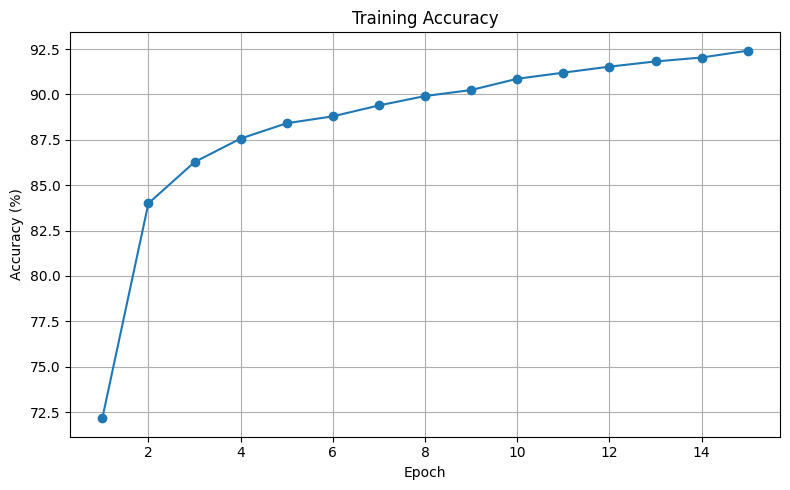

In [57]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)



plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    [acc * 100 for acc in history["train_acc"]],
    marker="o"
)

plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.tight_layout()
plt.show()








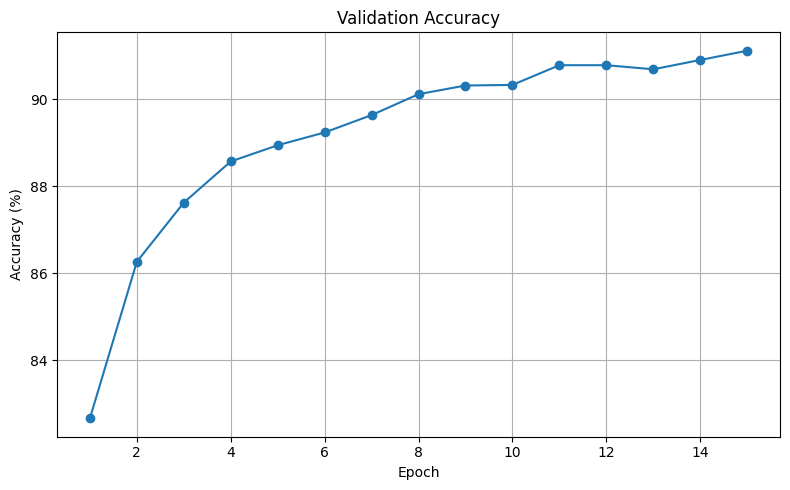

In [58]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    [acc * 100 for acc in history["val_acc"]],
    marker="o"
)

plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.tight_layout()
plt.show()


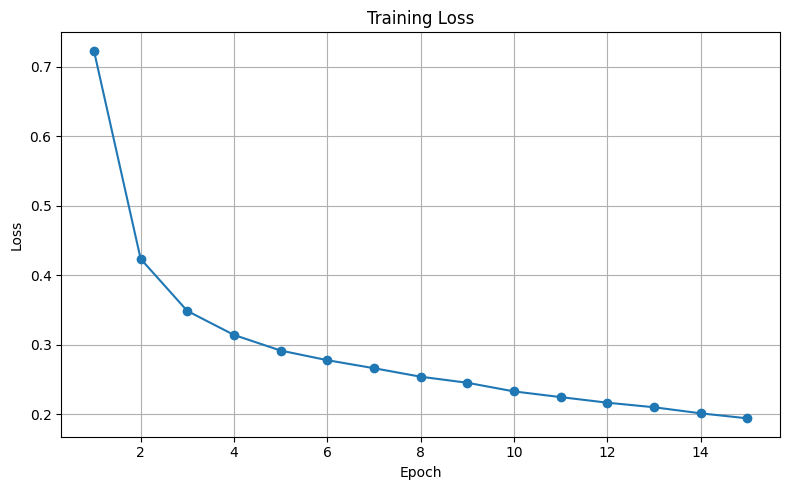

In [59]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o"
)

plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

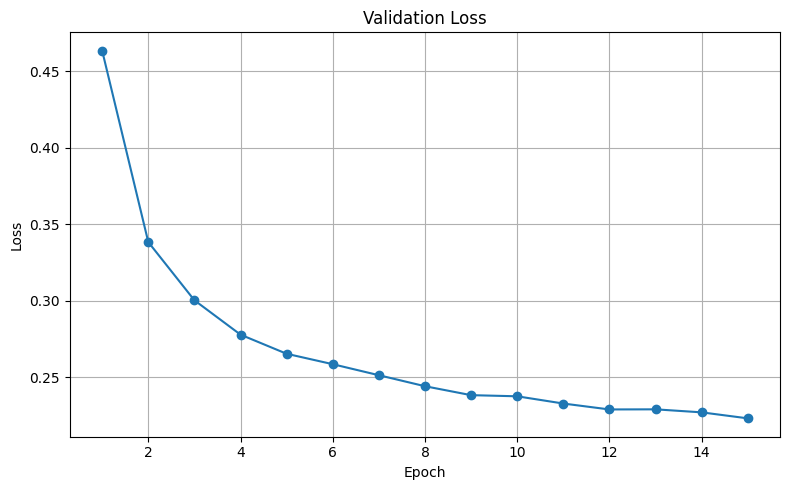

In [60]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["val_loss"],
    marker="o"
)

plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.tight_layout()
plt.show()